# Credit Card Fraud Detection Using Machine Learning

## Objective
Build a machine learning pipeline to identify potentially fraudulent credit card transactions in a highly imbalanced dataset.

## Dataset
Credit Card Fraud Detection dataset from Kaggle.

## Models
- Logistic Regression
- Random Forest Classifier

## Project Workflow
1. Load and inspect the dataset.
2. Analyze fraud class imbalance.
3. Explore transaction amounts and transaction times.
4. Split data using stratification.
5. Handle class imbalance using class weights.
6. Train and compare two classification models.
7. Evaluate precision, recall, F1-score, and ROC-AUC.
8. Analyze feature importance.
9. Discuss scalability and export results.

In [1]:
%pip install pandas numpy matplotlib seaborn scikit-learn

Note: you may need to restart the kernel to use updated packages.


In [2]:
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    roc_curve,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")

RANDOM_STATE = 42

print("Libraries imported successfully!")

Libraries imported successfully!


In [4]:
file_path = Path(r"C:\users\hi\Documents\OIBSIP\Fraud-Detection\ data\creditcard.csv")

if not file_path.exists():
    raise FileNotFoundError(
        "creditcard.csv was not found. Place it inside the data folder "
        "within the Fraud-Detection project."
    )

df = pd.read_csv(file_path)

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

print("\nColumn names:")
print(df.columns.tolist())

print("\nFirst five transactions:")
display(df.head())

print("\nDataset information:")
df.info()

Dataset loaded successfully!
Dataset shape: (284807, 31)

Column names:
['Time', 'V1', 'V2', 'V3', 'V4', 'V5', 'V6', 'V7', 'V8', 'V9', 'V10', 'V11', 'V12', 'V13', 'V14', 'V15', 'V16', 'V17', 'V18', 'V19', 'V20', 'V21', 'V22', 'V23', 'V24', 'V25', 'V26', 'V27', 'V28', 'Amount', 'Class']

First five transactions:


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0



Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 284807 entries, 0 to 284806
Data columns (total 31 columns):
 #   Column  Non-Null Count   Dtype  
---  ------  --------------   -----  
 0   Time    284807 non-null  float64
 1   V1      284807 non-null  float64
 2   V2      284807 non-null  float64
 3   V3      284807 non-null  float64
 4   V4      284807 non-null  float64
 5   V5      284807 non-null  float64
 6   V6      284807 non-null  float64
 7   V7      284807 non-null  float64
 8   V8      284807 non-null  float64
 9   V9      284807 non-null  float64
 10  V10     284807 non-null  float64
 11  V11     284807 non-null  float64
 12  V12     284807 non-null  float64
 13  V13     284807 non-null  float64
 14  V14     284807 non-null  float64
 15  V15     284807 non-null  float64
 16  V16     284807 non-null  float64
 17  V17     284807 non-null  float64
 18  V18     284807 non-null  float64
 19  V19     284807 non-null  float64
 20  V20     284807 non-null  float64
 21 

### Dataset Overview — Analysis

The dataset contains transaction features, transaction amounts, elapsed transaction times, and the target column `Class`.

- `Class = 0` represents a legitimate transaction.
- `Class = 1` represents a fraudulent transaction.
- Features `V1` to `V28` are anonymized numerical variables.
- `Amount` represents the transaction amount.
- `Time` represents elapsed time in seconds.

The dataset will be inspected before model training to understand its structure and fraud detection challenges.

## 1. Data Quality Analysis

Before training the models, we inspect missing values, duplicate rows, data types, and numerical summaries. This helps identify data quality issues that may affect model performance.

In [5]:
print("Missing values by column:")
display(df.isnull().sum().to_frame("Missing Values"))

print("Total missing values:", df.isnull().sum().sum())
print("Duplicate rows:", df.duplicated().sum())

print("\nNumerical summary:")
display(df.describe().T.round(3))

Missing values by column:


,Missing Values
Time,0
V1,0
V2,0
V3,0
V4,0
V5,0
V6,0
V7,0
V8,0
V9,0


Total missing values: 0
Duplicate rows: 1081

Numerical summary:


,count,mean,std,min,25%,50%,75%,max
Time,284807.0,94813.860,47488.146,0.000,54201.500,84692.000,139320.500,172792.000
V1,284807.0,0.000,1.959,-56.408,-0.920,0.018,1.316,2.455
V2,284807.0,0.000,1.651,-72.716,-0.599,0.065,0.804,22.058
V3,284807.0,-0.000,1.516,-48.326,-0.890,0.180,1.027,9.383
V4,284807.0,0.000,1.416,-5.683,-0.849,-0.020,0.743,16.875
V5,284807.0,0.000,1.380,-113.743,-0.692,-0.054,0.612,34.802
V6,284807.0,0.000,1.332,-26.161,-0.768,-0.274,0.399,73.302
V7,284807.0,-0.000,1.237,-43.557,-0.554,0.040,0.570,120.589
V8,284807.0,0.000,1.194,-73.217,-0.209,0.022,0.327,20.007
V9,284807.0,-0.000,1.099,-13.434,-0.643,-0.051,0.597,15.595


## 2. Fraud Class Distribution and Imbalance

Fraud detection datasets are usually highly imbalanced because legitimate transactions greatly outnumber fraudulent transactions. We calculate the number and percentage of each class to measure the severity of the imbalance.

,Transaction Type,Count,Percentage
0,Legitimate,284315,99.8273
1,Fraudulent,492,0.1727


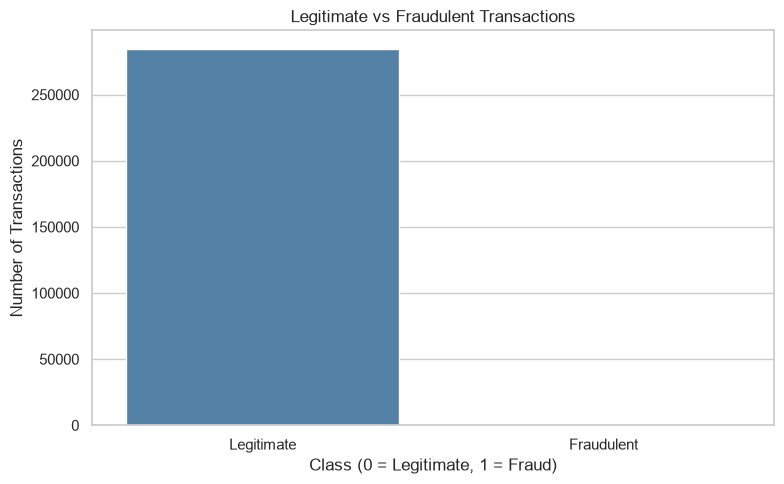

Percentage of fraudulent transactions: 0.1727%


In [6]:
class_counts = df["Class"].value_counts().sort_index()
class_percentages = df["Class"].value_counts(normalize=True).sort_index() * 100

class_summary = pd.DataFrame({
    "Transaction Type": ["Legitimate", "Fraudulent"],
    "Count": [
        class_counts.get(0, 0),
        class_counts.get(1, 0)
    ],
    "Percentage": [
        class_percentages.get(0, 0),
        class_percentages.get(1, 0)
    ]
})

class_summary["Percentage"] = class_summary["Percentage"].round(4)
display(class_summary)

plt.figure(figsize=(8, 5))
sns.countplot(data=df, x="Class", color="steelblue")
plt.title("Legitimate vs Fraudulent Transactions")
plt.xlabel("Class (0 = Legitimate, 1 = Fraud)")
plt.ylabel("Number of Transactions")
plt.xticks([0, 1], ["Legitimate", "Fraudulent"])
plt.tight_layout()
plt.show()

fraud_percentage = (df["Class"] == 1).mean() * 100
print(f"Percentage of fraudulent transactions: {fraud_percentage:.4f}%")

### Class Imbalance — Analysis

The fraud percentage is calculated from the actual dataset.

The dataset is heavily imbalanced: legitimate transactions form the majority, while fraud cases are rare. This can cause a model to favor legitimate transactions and miss fraud cases.

We will use `class_weight="balanced"` during model training to give greater weight to the minority class. We will also evaluate recall, precision, F1-score, and ROC-AUC rather than relying on accuracy alone.

## 3. Why Accuracy Is Misleading in Fraud Detection

Accuracy measures the proportion of all transactions classified correctly. However, it can be misleading when fraudulent transactions represent only a tiny fraction of the dataset.

For example, if only about 0.17% of transactions are fraudulent, a model that predicts every transaction as legitimate can achieve approximately 99.83% accuracy while detecting zero fraud cases.

Therefore, high accuracy does not necessarily mean that a fraud detection model is useful.

- **Recall:** Measures the proportion of actual fraud cases detected. Higher recall means fewer fraudulent transactions are missed.
- **Precision:** Measures the proportion of transactions predicted as fraud that are truly fraudulent. Higher precision means fewer legitimate transactions are incorrectly flagged.
- **F1-score:** Balances precision and recall.
- **ROC-AUC:** Measures how well the model ranks fraudulent transactions above legitimate ones across different classification thresholds.

For fraud detection, recall is often important because missed fraud can cause financial losses. However, precision must also be considered because too many false alarms can overwhelm investigators and inconvenience customers. The appropriate balance depends on the business's risk tolerance and review capacity.

## 4. Exploratory Data Analysis — Transaction Amounts

We compare transaction amounts for legitimate and fraudulent transactions. Because transaction amounts may be highly skewed, we use a logarithmic scale for visualization to make the distributions easier to inspect.

The original `Amount` values remain unchanged in the dataset.

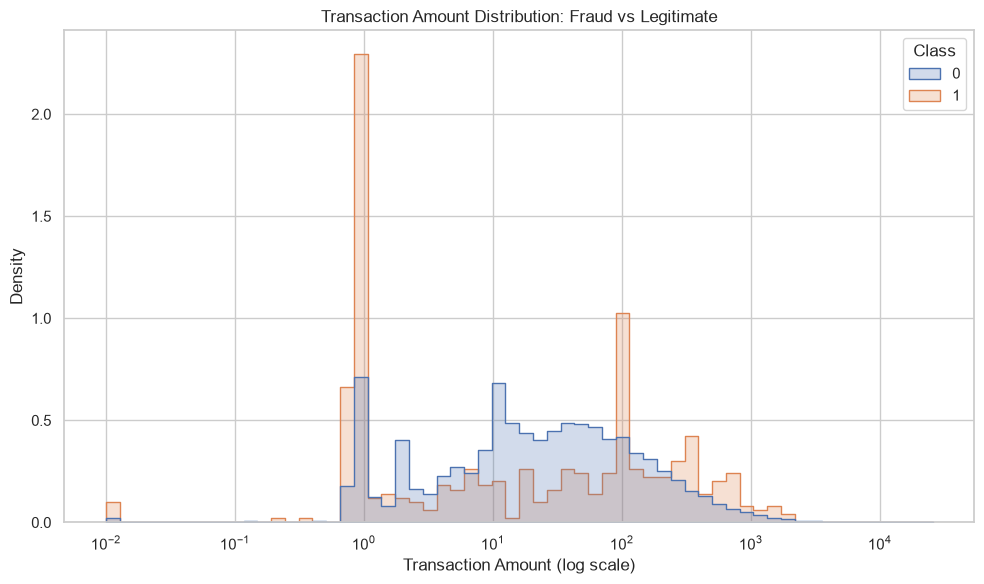

Transaction amount statistics by class:


,count,mean,median,min,max
Class,,,,,
0,284315,88.29,22.00,0.0,25691.16
1,492,122.21,9.25,0.0,2125.87


In [7]:
plt.figure(figsize=(10, 6))

sns.histplot(
    data=df,
    x="Amount",
    hue="Class",
    bins=60,
    stat="density",
    common_norm=False,
    element="step",
    log_scale=(True, False)
)

plt.title("Transaction Amount Distribution: Fraud vs Legitimate")
plt.xlabel("Transaction Amount (log scale)")
plt.ylabel("Density")
plt.tight_layout()
plt.show()

print("Transaction amount statistics by class:")
display(
    df.groupby("Class")["Amount"]
    .agg(["count", "mean", "median", "min", "max"])
    .round(2)
)

### Transaction Amount — Analysis

Compare the amount distributions and the summary statistics for the two classes.

Check whether fraudulent transactions appear concentrated in particular amount ranges or whether their distribution overlaps substantially with legitimate transactions.

The amount alone is not sufficient to identify fraud. The model must consider it alongside the other transaction features.

## 5. Transaction Time Analysis

The `Time` column records elapsed seconds from the beginning of the dataset's observation period. We convert it to an approximate elapsed hour within a 24-hour cycle to explore time-of-day patterns.

This is an exploratory approximation because the dataset does not provide a calendar timestamp or timezone.

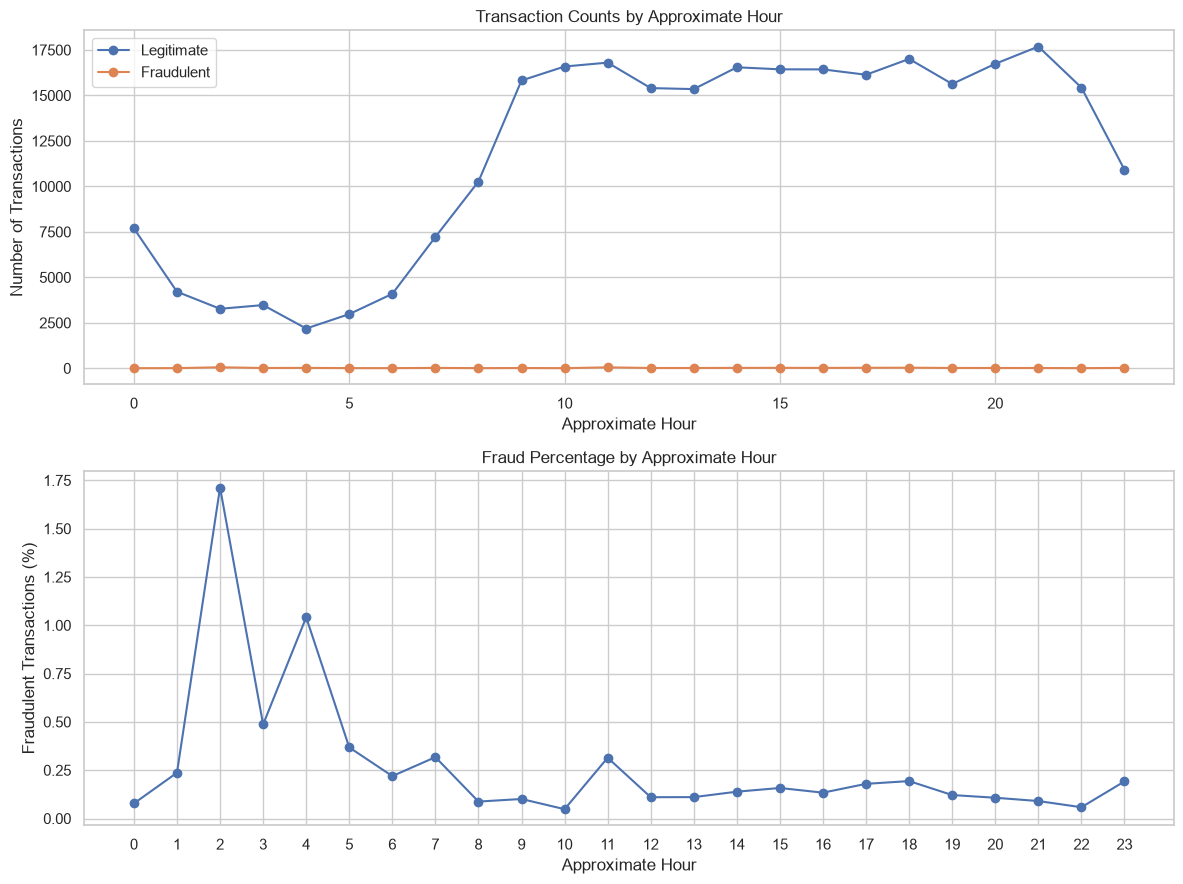

In [8]:
time_df = df[["Time", "Class"]].copy()
time_df["Hour_Approx"] = ((time_df["Time"] // 3600) % 24).astype(int)

hourly_counts = (
    time_df.groupby(["Hour_Approx", "Class"])
    .size()
    .unstack(fill_value=0)
    .reindex(range(24), fill_value=0)
)

hourly_rates = (
    time_df.groupby("Hour_Approx")["Class"]
    .mean()
    .reindex(range(24))
    * 100
)

fig, axes = plt.subplots(2, 1, figsize=(12, 9))

hourly_counts.plot(kind="line", marker="o", ax=axes[0])
axes[0].set_title("Transaction Counts by Approximate Hour")
axes[0].set_xlabel("Approximate Hour")
axes[0].set_ylabel("Number of Transactions")
axes[0].legend(["Legitimate", "Fraudulent"])

axes[1].plot(hourly_rates.index, hourly_rates.values, marker="o")
axes[1].set_title("Fraud Percentage by Approximate Hour")
axes[1].set_xlabel("Approximate Hour")
axes[1].set_ylabel("Fraudulent Transactions (%)")
axes[1].set_xticks(range(24))

plt.tight_layout()
plt.show()

### Time Analysis — Analysis

Inspect the number of transactions and the fraud percentage by approximate hour.

Some hours may have more transactions or a different fraud rate than others. Interpret the results cautiously because `Time` is elapsed time rather than a real timestamp, and hourly patterns may be affected by the dataset's observation window.

The chart is exploratory; it does not prove that a particular time causes fraud.

## 6. Train/Test Split

We separate the predictors from the target column `Class`. The dataset is split into 80% training data and 20% testing data.

Stratification ensures that both sets contain approximately the same proportion of fraudulent transactions. This is especially important because fraud cases are rare.

We will not apply oversampling before splitting, because that could leak information from the test set into the training process.

In [9]:
X = df.drop(columns=["Class"]).copy()
y = df["Class"].copy()

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y
)

print("Training set:", X_train.shape)
print("Testing set:", X_test.shape)

print("\nTraining class percentages:")
display((y_train.value_counts(normalize=True) * 100).round(4).to_frame("Percentage"))

print("\nTesting class percentages:")
display((y_test.value_counts(normalize=True) * 100).round(4).to_frame("Percentage"))

print("\nFraud cases in training set:", int(y_train.sum()))
print("Fraud cases in testing set:", int(y_test.sum()))

Training set: (227845, 30)
Testing set: (56962, 30)

Training class percentages:


,Percentage
Class,
0,99.8271
1,0.1729



Testing class percentages:


,Percentage
Class,
0,99.828
1,0.172



Fraud cases in training set: 394
Fraud cases in testing set: 98


### Train/Test Split — Analysis

Check that both training and testing sets contain fraudulent transactions and that their fraud percentages are similar.

The training set is used to fit the models. The test set is kept separate for the final evaluation on unseen data.

## 7. Model Training and Imbalance Handling

We train two classifiers:

1. **Logistic Regression:** a baseline classification model that estimates the probability of fraud.
2. **Random Forest:** an ensemble of decision trees that can learn nonlinear relationships.

Both models use `class_weight="balanced"`. This increases the relative importance of minority-class examples during training.

For Logistic Regression, StandardScaler is fitted only on training data through a pipeline. Random Forest does not require standard scaling. The test set is not used for fitting either model.

In [10]:
models = {
    "Logistic Regression": Pipeline([
        ("scaler", StandardScaler()),
        ("classifier", LogisticRegression(
            class_weight="balanced",
            max_iter=1000,
            random_state=RANDOM_STATE
        ))
    ]),

    "Random Forest": RandomForestClassifier(
        n_estimators=100,
        class_weight="balanced",
        random_state=RANDOM_STATE,
        n_jobs=-1
    )
}

trained_models = {}
model_probabilities = {}
model_predictions = {}

for name, model in models.items():
    print(f"Training {name}...")

    model.fit(X_train, y_train)
    trained_models[name] = model

    model_probabilities[name] = model.predict_proba(X_test)[:, 1]
    model_predictions[name] = model.predict(X_test)

    print(f"{name} training completed.\n")

print("Both models have been trained successfully!")

Training Logistic Regression...
Logistic Regression training completed.

Training Random Forest...
Random Forest training completed.

Both models have been trained successfully!


### Model Training — Analysis

Both models use the same stratified training set and class-weighting strategy.

Class weighting helps address the imbalance during learning, but it does not guarantee high fraud recall or precision. We will assess the actual test-set metrics before deciding which model is more suitable.

## 8. Model Evaluation

We evaluate each classifier using precision, recall, F1-score, accuracy, and ROC-AUC.

Fraud is the positive class (`Class = 1`). Recall measures how many actual fraud cases were detected, while precision measures how many flagged transactions were truly fraudulent. ROC-AUC uses the predicted probabilities and assesses ranking performance across thresholds.

In [11]:
evaluation_results = []

for name in trained_models:
    y_pred = model_predictions[name]
    y_prob = model_probabilities[name]

    metrics = {
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred, zero_division=0),
        "Recall": recall_score(y_test, y_pred, zero_division=0),
        "F1-Score": f1_score(y_test, y_pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y_test, y_prob)
    }

    evaluation_results.append(metrics)

    print("=" * 60)
    print(name)
    print("=" * 60)
    print(classification_report(
        y_test,
        y_pred,
        labels=[0, 1],
        target_names=["Legitimate", "Fraud"],
        zero_division=0
    ))

comparison_df = pd.DataFrame(evaluation_results)
display(comparison_df.round(4))

Logistic Regression
              precision    recall  f1-score   support

  Legitimate       1.00      0.98      0.99     56864
       Fraud       0.06      0.92      0.11        98

    accuracy                           0.98     56962
   macro avg       0.53      0.95      0.55     56962
weighted avg       1.00      0.98      0.99     56962

Random Forest
              precision    recall  f1-score   support

  Legitimate       1.00      1.00      1.00     56864
       Fraud       0.91      0.79      0.84        98

    accuracy                           1.00     56962
   macro avg       0.95      0.89      0.92     56962
weighted avg       1.00      1.00      1.00     56962



,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,Logistic Regression,0.9755,0.0610,0.9184,0.1144,0.9721
1,Random Forest,0.9995,0.9059,0.7857,0.8415,0.9573


### Evaluation — Analysis

Use the comparison table to assess how well each model detects fraud.

- Higher recall means fewer actual fraud cases are missed.
- Higher precision means fewer legitimate transactions are flagged as fraud.
- Higher F1-score indicates a stronger balance between precision and recall.
- Higher ROC-AUC indicates better ranking of fraudulent transactions above legitimate transactions.

Accuracy is included for context, but it should not be the main selection criterion for this imbalanced dataset.

## 9. Confusion Matrix Analysis

A confusion matrix shows correct and incorrect classifications for legitimate and fraudulent transactions. In particular, false negatives are fraudulent transactions incorrectly classified as legitimate, while false positives are legitimate transactions incorrectly flagged as fraud.

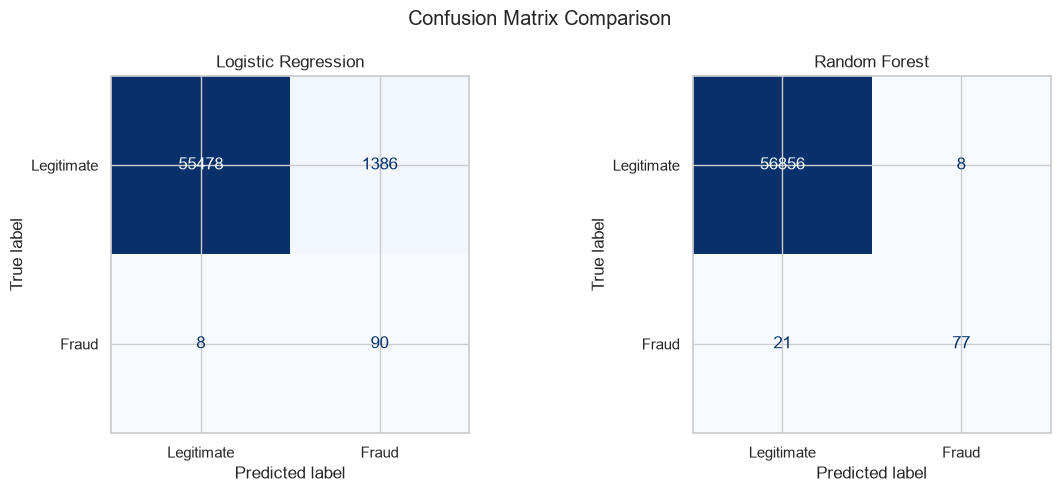

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for ax, (name, y_pred) in zip(axes, model_predictions.items()):
    cm = confusion_matrix(y_test, y_pred, labels=[0, 1])

    disp = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=["Legitimate", "Fraud"]
    )
    disp.plot(ax=ax, cmap="Blues", values_format="d", colorbar=False)
    ax.set_title(name)

plt.suptitle("Confusion Matrix Comparison")
plt.tight_layout()
plt.show()

### Confusion Matrix — Analysis

- **True negatives:** legitimate transactions correctly identified.
- **True positives:** fraudulent transactions correctly detected.
- **False positives:** legitimate transactions incorrectly flagged.
- **False negatives:** fraudulent transactions missed by the model.

For fraud detection, false negatives can result in financial losses. False positives can create unnecessary investigations or customer inconvenience. The preferred balance depends on the business's risk tolerance.

## 10. ROC Curve and AUC Comparison

The Receiver Operating Characteristic (ROC) curve plots the true positive rate against the false positive rate at different classification thresholds. The Area Under the Curve (ROC-AUC) summarizes the model's ability to rank fraud cases above legitimate cases.

The curve helps compare models beyond their default classification threshold.

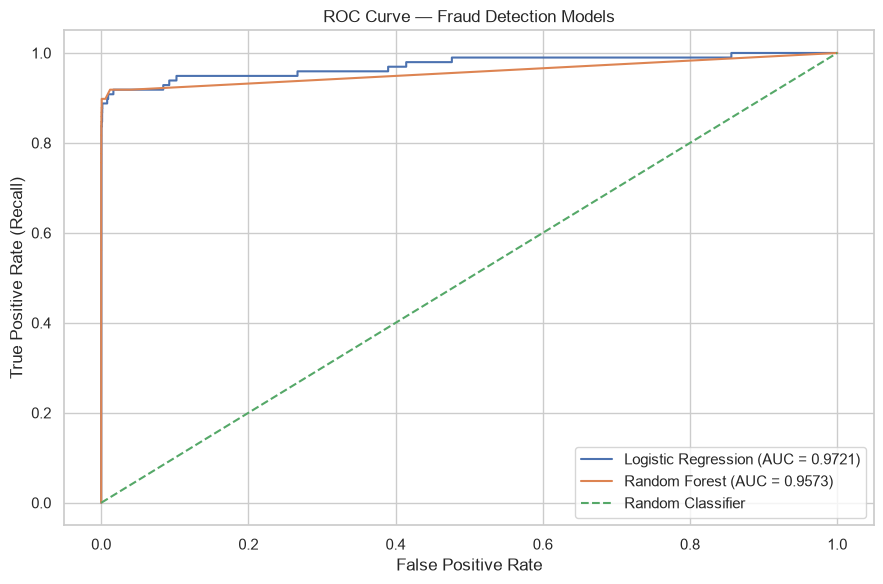

In [13]:
plt.figure(figsize=(9, 6))

for name, y_prob in model_probabilities.items():
    fpr, tpr, thresholds = roc_curve(y_test, y_prob)
    auc_value = roc_auc_score(y_test, y_prob)

    plt.plot(
        fpr,
        tpr,
        label=f"{name} (AUC = {auc_value:.4f})"
    )

plt.plot([0, 1], [0, 1], linestyle="--", label="Random Classifier")
plt.title("ROC Curve — Fraud Detection Models")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate (Recall)")
plt.legend()
plt.tight_layout()
plt.show()

### ROC-AUC — Analysis

Compare the ROC curves and their AUC values. A curve closer to the top-left corner generally indicates stronger discrimination.

A higher ROC-AUC is useful, but it does not guarantee high precision at the default threshold or at a business-specific operating point. Review recall and precision alongside ROC-AUC when choosing a model.

## 11. Feature Importance and Coefficient Analysis

We examine Random Forest feature importance to identify which transaction variables contribute most to the model's predictions. We also inspect Logistic Regression coefficients to understand the direction of its learned relationships.

These results describe the fitted models; they do not prove that a feature causes fraud.

,Feature,Importance
14,V14,0.191038
10,V10,0.106849
4,V4,0.105643
12,V12,0.097603
17,V17,0.090339
3,V3,0.065919
11,V11,0.046342
16,V16,0.044655
2,V2,0.038335
9,V9,0.025445


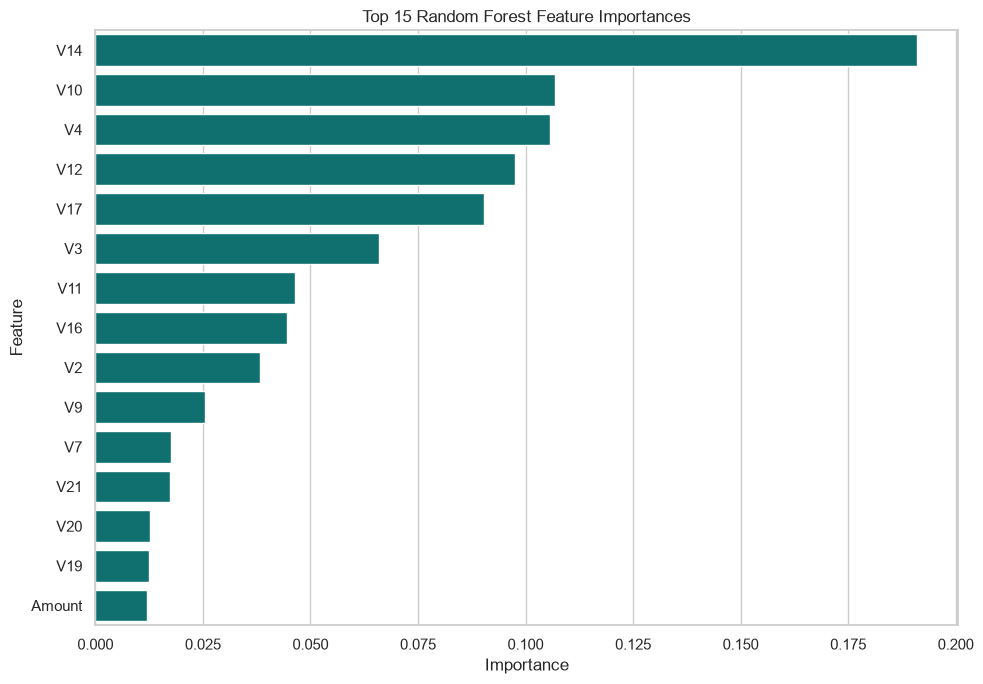

,Feature,Coefficient,Absolute Coefficient
29,Amount,2.367276,2.367276
1,V1,1.723862,1.723862
14,V14,-1.494961,1.494961
4,V4,1.339431,1.339431
10,V10,-1.334996,1.334996
5,V5,1.214379,1.214379
12,V12,-1.127886,1.127886
16,V16,-0.996376,0.996376
17,V17,-0.992185,0.992185
2,V2,0.932075,0.932075


In [14]:
rf_model = trained_models["Random Forest"]

feature_importance = pd.DataFrame({
    "Feature": X_train.columns,
    "Importance": rf_model.feature_importances_
}).sort_values("Importance", ascending=False)

display(feature_importance.head(15))

plt.figure(figsize=(10, 7))
sns.barplot(
    data=feature_importance.head(15),
    x="Importance",
    y="Feature",
    color="teal"
)
plt.title("Top 15 Random Forest Feature Importances")
plt.xlabel("Importance")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()

logistic_model = trained_models["Logistic Regression"].named_steps["classifier"]

coefficients = pd.DataFrame({
    "Feature": X_train.columns,
    "Coefficient": logistic_model.coef_[0]
})

coefficients["Absolute Coefficient"] = coefficients["Coefficient"].abs()
coefficients = coefficients.sort_values(
    "Absolute Coefficient",
    ascending=False
)

display(coefficients.head(15))

### Feature Analysis

The Random Forest chart ranks features by their impurity-based importance. Logistic Regression coefficients indicate the direction and magnitude of the learned relationship on the scaled feature inputs.

Use the actual output to identify the most influential features. Because `V1`–`V28` are anonymized, their underlying real-world meanings cannot be determined from this dataset alone.

## 12. Final Model Comparison and Export

We compare both models using precision, recall, F1-score, and ROC-AUC. The results and feature analysis are exported to CSV files for reporting and further review.

,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,Logistic Regression,0.9755,0.0610,0.9184,0.1144,0.9721
1,Random Forest,0.9995,0.9059,0.7857,0.8415,0.9573


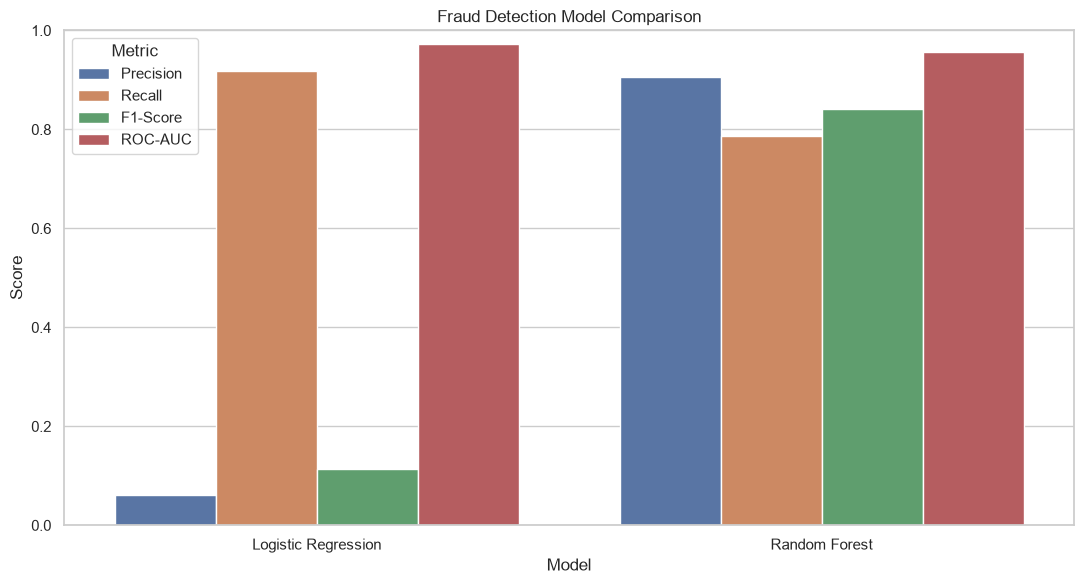

All result files saved successfully:
C:\Users\hi\Documents\OIBSIP\Fraud-Detection\output\fraud_predictions.csv
C:\Users\hi\Documents\OIBSIP\Fraud-Detection\output\logistic_regression_coefficients.csv
C:\Users\hi\Documents\OIBSIP\Fraud-Detection\output\model_comparison.csv
C:\Users\hi\Documents\OIBSIP\Fraud-Detection\output\random_forest_feature_importance.csv


In [15]:
comparison_df = comparison_df.sort_values(
    by="Recall",
    ascending=False
).reset_index(drop=True)

display(comparison_df.round(4))

comparison_long = comparison_df.melt(
    id_vars="Model",
    value_vars=["Precision", "Recall", "F1-Score", "ROC-AUC"],
    var_name="Metric",
    value_name="Score"
)

plt.figure(figsize=(11, 6))
sns.barplot(
    data=comparison_long,
    x="Model",
    y="Score",
    hue="Metric"
)
plt.title("Fraud Detection Model Comparison")
plt.ylim(0, 1)
plt.tight_layout()
plt.show()

output_dir = Path("output")
output_dir.mkdir(parents=True, exist_ok=True)

comparison_df.to_csv(
    output_dir / "model_comparison.csv",
    index=False
)

feature_importance.to_csv(
    output_dir / "random_forest_feature_importance.csv",
    index=False
)

coefficients.to_csv(
    output_dir / "logistic_regression_coefficients.csv",
    index=False
)

prediction_output = pd.DataFrame({
    "Actual_Class": y_test.to_numpy()
})

for name in trained_models:
    prediction_output[f"{name.replace(' ', '_')}_Prediction"] = (
        model_predictions[name]
    )
    prediction_output[f"{name.replace(' ', '_')}_Fraud_Probability"] = (
        model_probabilities[name]
    )

prediction_output.to_csv(
    output_dir / "fraud_predictions.csv",
    index=False
)

print("All result files saved successfully:")
for path in sorted(output_dir.glob("*.csv")):
    print(path.resolve())

### Model Comparison — Analysis

Compare precision, recall, F1-score, and ROC-AUC for both models.

If missing fraudulent transactions is the primary concern, a model with higher recall may be preferable. However, review precision and the number of false positives before choosing a model for practical use.

The exported CSV files preserve the evaluation results, feature importance, coefficients, and test-set predictions.

## 13. Scalability Considerations

One million transactions per hour is approximately 278 transactions per second. A production fraud detection system would need to process incoming transactions reliably while meeting latency and availability requirements.

Potential improvements include:

1. **Streaming ingestion:** Use a distributed event platform such as Apache Kafka to receive transaction events.
2. **Fast inference:** Deploy a trained model as a low-latency service and benchmark its throughput.
3. **Batch processing:** Use batch scoring where immediate decisions are not required.
4. **Feature engineering:** Precompute reusable features and avoid expensive calculations in the real-time request path.
5. **Monitoring:** Track latency, throughput, fraud recall, false-positive rates, data drift, and changes in fraud patterns.
6. **Model updates:** Retrain and validate periodically using appropriately labelled transactions.
7. **Fallback handling:** Design for timeouts, service failures, and safe transaction review when predictions are unavailable.

A million transactions per hour is a design target, not a performance result demonstrated by this notebook. The actual capacity must be validated through load testing, infrastructure sizing, and latency measurements.

## 14. Conclusion

This project developed a machine learning workflow for credit card fraud detection using a highly imbalanced transaction dataset.

Exploratory analysis examined fraud prevalence, transaction amounts, and approximate time patterns. Stratified train/test splitting preserved the representation of fraud cases in both sets, while class weighting helped address imbalance during training.

Logistic Regression and Random Forest were evaluated using precision, recall, F1-score, confusion matrices, and ROC-AUC. Random Forest feature importance and Logistic Regression coefficients were also examined.

The final model should be selected using the measured evaluation results and the business cost of missed fraud versus false alarms. Recall is particularly important when undetected fraud is costly, but precision must remain acceptable for the investigation team.

Further work could include threshold tuning, testing on later time periods, monitoring data drift, and load testing a production deployment.